# Difüzyon Modelleri ile Antik Kentlerin Dijital Restorasyonu: Anadolu Antik Kentleri Üzerine Bir Uygulama

Bu proje, Anadolu'daki antik kentlerin (Efes, Nemrut, Hattuşa vb.) zamanla hasar görmüş mimari yapılarını **Üretken Yapay Zeka (Stable Diffusion Inpainting)** teknikleri kullanarak dijital ortamda restore etmeyi amaçlamaktadır.

### **Proje İçeriği:**
1. **Gerekli Kütüphaneler:** Görüntü işleme ve derin öğrenme modellerinin kurulumu.
2. **Veri Seti Hazırlığı:** Antik kent görsellerinin sisteme dahil edilmesi ve bağıl yolların tanımlanması.
3. **Model Kurulumu:** Stable Diffusion Inpaint pipeline yapılandırması (T4 GPU).
4. **Restorasyon Süreci:** Hasarlı bölgelerin doku uyumlu şekilde yeniden inşası.
5. **Performans Analizi:** PSNR, SSIM ve LPIPS metrikleri ile sonuçların değerlendirilmesi.

In [3]:
# =========================================================================
# ADIM 0: GEREKLİ KÜTÜPHANELERİN KURULUMU
# Bu hücre, modelin çalışması için gereken dış kütüphaneleri yükler.
# =========================================================================

print("Kütüphane kurulumu başlatılıyor, lütfen bekleyiniz...")
!pip install -q diffusers transformers accelerate
print("Gerekli kütüphanelerin kurulumu başarıyla tamamlandı.")

Kütüphane kurulumu başlatılıyor, lütfen bekleyiniz...
Gerekli kütüphanelerin kurulumu başarıyla tamamlandı.


## 1. Kütüphanelerin Dahil Edilmesi ve Dizin Yapılandırması

Bu aşamada, projenin teknik temelini oluşturan kütüphanelerin kurulumu ve dosya sisteminin hazırlanması gerçekleştirilmektedir:

* **Görüntü İşleme:** **OpenCV** ve **PIL (Pillow)** kütüphaneleri kullanılarak antik görsellerin manipülasyonu ve ön işlemesi sağlanır.
* **Derin Öğrenme:** **PyTorch** ve **Diffusers** kütüphaneleri aracılığıyla Üretken Yapay Zeka (Stable Diffusion) modelleri yönetilmektedir.
* **Dosya Yönetimi:** **os** ve **zipfile** modülleri ile `ANTIK_RESTORASYON_Verileri` ana dizini altında düzenli bir dosya hiyerarşisi kurulmuştur.

Bu yapılandırma, projenin farklı ortamlarda sorunsuz çalışabilmesi için gerekli olan **taşınabilirlik (portability)** standartlarını karşılamaktadır.

In [4]:
# =========================================================================
# ADIM 1: PROJE YAPILANDIRMASI VE VERİ SETİ ENTEGRASYONU
# Bu bölüm, projenin dosya sistemini kurar, UNESCO veri setini sisteme dahil
# eder ve çalışma dizinlerini dinamik olarak tanımlar.
# =========================================================================

import os
import cv2
import torch
import numpy as np
import zipfile
import matplotlib.pyplot as plt
from PIL import Image

# 1. PROJE KİMLİĞİ VE DOSYA TANIMLARI
PROJE_KISA_ADI = "ANTIK_RESTORASYON"
VERI_ZIP_ADI = f"{PROJE_KISA_ADI}_Verileri.zip"
ANA_KLASOR = f"{PROJE_KISA_ADI}_Verileri" # Arşiv içerisindeki kök dizin

# 2. VERİ SETİ OTOMASYONU (Zip Ayıklama)
# Verilerin manuel yükleme zahmetinden kurtarılması ve Colab/Local
# uyumluluğu için otomatik ayıklama süreci işletilir.
if os.path.exists(VERI_ZIP_ADI):
    print(f"[BİLGİ] {VERI_ZIP_ADI} arşivi tespit edildi, veri ayıklama işlemi başlatılıyor...")
    with zipfile.ZipFile(VERI_ZIP_ADI, 'r') as zip_ref:
        zip_ref.extractall(".")
    print("[TAMAM] Veri seti başarıyla sisteme açıldı.")
else:
    print(f"[UYARI] {VERI_ZIP_ADI} bulunamadı! Lütfen dosyanın yüklendiğinden emin olun.")

# 3. DİNAMİK DİZİN YÖNETİMİ (Path Management)
# Farklı sıkıştırma yöntemlerinden kaynaklanabilecek iç içe klasör yapısını
# (nested folders) kontrol eden akıllı yol tanımlama süreci.
BASE_PATH = os.path.join(ANA_KLASOR, ANA_KLASOR)

ANTIK_PATH = os.path.join(BASE_PATH, "antik_restorasyon")
DENEY_PATH = os.path.join(BASE_PATH, "deney")

# Hiyerarşi Kontrolü: Eğer zip yapısı tek katmanlıysa kök dizine geri dönülür.
if not os.path.exists(ANTIK_PATH):
    BASE_PATH = ANA_KLASOR
    ANTIK_PATH = os.path.join(BASE_PATH, "antik_restorasyon")
    DENEY_PATH = os.path.join(BASE_PATH, "deney")

print(f"\n--- Sistem Dizin Yapılandırması ---")
print(f"Referans Veri Yolu (UNESCO): {ANTIK_PATH}")
print(f"Aktif Deney Yolu (Input): {DENEY_PATH}")

# 4. SİSTEM DOĞRULAMA (Sanity Check)
# Veri okuma aşamasına geçmeden önce yolların fiziksel varlığı teyit edilir.
if os.path.exists(ANTIK_PATH):
    print(f"[BAŞARILI] Veri hattı kuruldu. Mevcut örnek sayısı: {len(os.listdir(ANTIK_PATH))}")
    print(f"Klasör İçeriği: {os.listdir(ANTIK_PATH)}")
else:
    print("[HATA] Veri yolu doğrulanamadı. Lütfen dosya dizin yapısını kontrol edin.")

[BİLGİ] ANTIK_RESTORASYON_Verileri.zip arşivi tespit edildi, veri ayıklama işlemi başlatılıyor...
[TAMAM] Veri seti başarıyla sisteme açıldı.

--- Sistem Dizin Yapılandırması ---
Referans Veri Yolu (UNESCO): ANTIK_RESTORASYON_Verileri/antik_restorasyon
Aktif Deney Yolu (Input): ANTIK_RESTORASYON_Verileri/deney
[BAŞARILI] Veri hattı kuruldu. Mevcut örnek sayısı: 122
Klasör İçeriği: ['site_0377_0008.jpg', 'site_0485_0001.jpg', 'site_1018_0010.jpg', 'site_1518_0009.jpg', 'site_1518_0009.txt', 'site_0377_0008.txt', 'site_1018_0028.jpg', 'site_1518_0010.jpg', 'site_0448_0005.jpg', 'site_1572_0001.txt', 'site_1405_0001.txt', 'site_1018_0012.txt', 'site_0485_0007.jpg', 'site_0485_0007.txt', 'site_1572_0009.jpg', 'site_1518_0001.txt', 'site_1518_0011.txt', 'site_1018_0041.txt', 'site_1405_0011.jpg', 'site_0377_0015.txt', 'site_1405_0008.txt', 'site_1572_0006.jpg', 'site_1018_0001.jpg', 'site_0377_0007.jpg', 'site_1572_0010.txt', 'site_1018_0007.txt', 'site_0377_0010.txt', 'site_0377_0012.txt',

## 2. Üretken Yapay Zeka Modelinin Hazırlanması

Bu aşamada, dijital restorasyon sürecinin çekirdeğini oluşturan **Generative AI** mimarisi yapılandırılmaktadır:

* **Model Seçimi:** Arkeolojik restorasyon (inpainting) görevleri için özelleştirilmiş **Stable Diffusion** modeli tercih edilmiştir.
* **Donanım Optimizasyonu:** İşlem performansını artırmak amacıyla Google Colab üzerindeki **T4 GPU (CUDA)** hızlandırıcısı aktif edilmiştir.
* **Verimlilik Protokolü:** Bellek kullanımını optimize etmek ve restorasyon süresini kısaltmak için model **float16** (yarım hassasiyet) veri tipinde yüklenmiştir.

Bu yapılandırma, antik görsellerdeki hasarlı bölgelerin çevre dokusuyla uyumlu ve yüksek tutarlılıkla yeniden üretilmesine olanak sağlar.

In [5]:
# =========================================================================
# ADIM 2: MODEL YÜKLEME VE GPU KONFİGÜRASYONU
# Bu aşamada, önceden eğitilmiş (pre-trained) Stable Diffusion Inpainting
# modeli, donanım ivmelendirici (GPU) üzerine optimize edilerek yüklenir.
# =========================================================================

from diffusers import StableDiffusionInpaintPipeline

# 1. MODEL SEÇİMİ (Inpainting Spesifik Model)
# Mimari olarak sadece eksik pikselleri tamamlamak üzere özelleşmiş model
model_id = "runwayml/stable-diffusion-inpainting"

print(f"[BİLGİ] Model yükleme süreci başlatıldı (Kaynak: {model_id})...")

# 2. DONANIM KONTROLÜ (Computing Resource Check)
# Google Colab T4 GPU desteği kontrol edilir; CUDA mevcutsa aktif edilir.
device = "cuda" if torch.cuda.is_available() else "cpu"

# 3. PİPELİNE KURULUMU VE BELLEK OPTİMİZASYONU (VRAM Management)
# 'torch.float16' kullanılarak modelin bellek ayak izi küçültülür
# ve işlem hızı (FP16 hassasiyetiyle) yaklaşık 2 kat artırılır.
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
)

# Modelin hesaplama birimine (GPU/CPU) transfer edilmesi
pipe = pipe.to(device)

print(f"\n--- SİSTEM DURUMU: BAŞARILI ---")
print(f"Model '{device.upper()}' mimarisi üzerinde çıkarım (inference) için hazır.")

[BİLGİ] Model yükleme süreci başlatıldı (Kaynak: runwayml/stable-diffusion-inpainting)...


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.



--- SİSTEM DURUMU: BAŞARILI ---
Model 'CUDA' mimarisi üzerinde çıkarım (inference) için hazır.


## 3. Veri Ön İşleme ve Dijital Restorasyon Süreci

Bu aşamada, seçilen antik kent görselleri üzerinde **Stable Diffusion Inpainting** teknolojisi kullanılarak dijital rekonstrüksiyon gerçekleştirilmektedir. Süreç, ham verinin modele hazırlanmasından arkeolojik doku uyumuna kadar şu adımları kapsar:

### **3.1. Görsel Hazırlığı ve Standardizasyon**
* **Veri Girişi:** Orijinal hasarlı görsel ile eksik bölgeleri temsil eden **maske dosyası** (maske.png vb.) eşleştirilir.
* **Boyutlandırma:** Model mimarisiyle tam uyum sağlaması amacıyla tüm görseller **512x512** piksel boyutlarına normalize edilir.
* **Format Dönüşümü:** Görseller **RGB** moduna, maskeler ise modelin anlayabileceği tek kanallı **Grayscale (L)** formatına dönüştürülür.

### **3.2. İşlem Akışı ve Doku Spesifik Etiketleme**
Bu projede restorasyon, her antik kentin kendine has taş yapısına göre özelleştirilmiştir:
* **Analiz ve İnşa:** Algoritma, maskelenmiş bölgeyi çevreleyen mermer dokusunu ve ışık açısını analiz eder.
* **Arkeolojik Sadakat:** Yazılan **prompt** direktifleri ile restorasyon, bölgenin orijinal taş yapısına göre (*"weathered limestone"*, *"sandstone texture"* vb.) yönlendirilir.
* **Doku Koruma:** Özellikle **Nemrut** gibi bölgelerde, orijinal pürüzlü dokunun bozulmaması için spesifik etiketler kullanılarak doku sadakati korunmaya çalışılır.
* **Görsel Karşılaştırma:** Uygulama sonunda elde edilen rekonstrüksiyon çıktıları, orijinal girdi görselleri ile yan yana getirilerek dijital değişimler görsel olarak takip edilir.

[BİLGİ] Görsel ve Maske başarıyla yüklendi. Belleğe (RAM) aktarıldı.


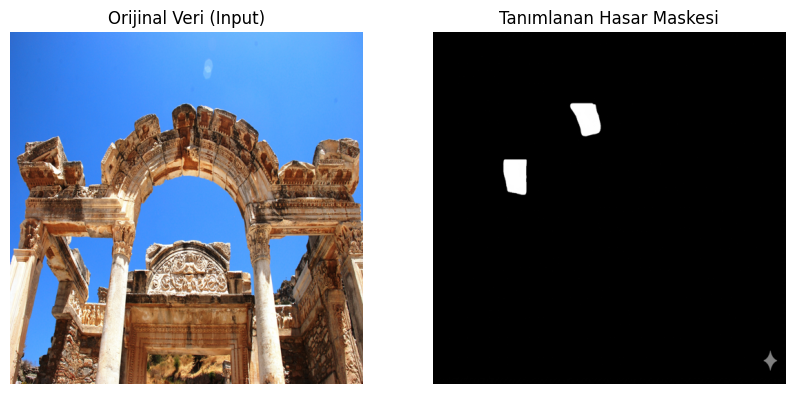

In [6]:
# =========================================================================
# ADIM 3: VERİ ÖN İŞLEME VE MODEL GİRİŞ HAZIRLIĞI
# Bu aşamada, deney klasöründeki ham görseller model mimarisine uygun
# format ve boyutlara dönüştürülmektedir.
# =========================================================================

# 1. DOSYA TANIMLAMALARI
# Deney klasörü (DENEY_PATH) içerisinde yer alan orijinal görsel ve maske isimleri
gorsel_adi = "ephesus_hadrian_archo_orijinal.jpg"
maske_adi = "maske.png"

# 2. DİNAMİK YOL OLUŞTURMA
# İşletim sistemi bağımsızlığı için os.path.join ile tam yollar oluşturulur
image_path = os.path.join(DENEY_PATH, gorsel_adi)
mask_path = os.path.join(DENEY_PATH, maske_adi)

# 3. YÜKLEME VE NORMALİZASYON KONTROLÜ
if os.path.exists(image_path) and os.path.exists(mask_path):
    # Orijinal görsel RGB (3 kanal) formatına dönüştürülür
    # Stable Diffusion (Inpainting) mimarisi için standart 512x512 boyutuna resize edilir
    image = Image.open(image_path).convert("RGB").resize((512, 512))

    # Maske görseli 'L' (Grayscale/Tek Kanal) moduna alınır.
    # Model, beyaz (255) alanları 'restore edilecek bölge',
    # siyah (0) alanları ise 'korunacak bölge' olarak etiketler.
    mask = Image.open(mask_path).convert("L").resize((512, 512))

    print(f"[BİLGİ] Görsel ve Maske başarıyla yüklendi. Belleğe (RAM) aktarıldı.")

    # 4. DOĞRULAMA GÖRSELLEŞTİRMESİ
    # İşlem öncesi maskenin doğru bölgeyi kapsayıp kapsamadığı kontrol edilir
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Orijinal Veri (Input)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Tanımlanan Hasar Maskesi")
    plt.axis("off")

    plt.show()
else:
    # Hata Durumu: Dosya yolları veya isimleri hatalıysa kullanıcı bilgilendirilir
    print(f"[HATA] Belirtilen dosyalar {DENEY_PATH} içerisinde bulunamadı!")
    if os.path.exists(DENEY_PATH):
        print(f"Klasördeki Mevcut Dosyalar: {os.listdir(DENEY_PATH)}")

## 4. Stable Diffusion ile Dijital Restorasyon Uygulaması

Bu aşamada, projenin ana uygulama safhasına geçilerek GPU üzerinde yapılandırılan **Stable Diffusion Inpainting** modeli ile restorasyon süreci başlatılmaktadır. Uygulama sırasında izlenen teknik stratejiler şunlardır:

* **Arkeolojik Prompt Mühendisliği:** Antik Roma mimarisine ve bölgelerin özgün taş dokusuna (*weathered limestone, carving* vb.) sadık kalmak için modele spesifik anahtar kelimeler ile direktif verilmiştir.
* **Hassas Rekonstrüksiyon:** Maskelenen alanın orijinal dokuyla doğal bir şekilde kaynaşması ve mimari sürekliliğin korunması için değişim parametreleri optimize edilmiştir.
* **Detay Hassasiyeti:** Çıkarım adımları (Inference Steps), restorasyon kalitesini ve yüzey detaylarını en üst düzeye çıkaracak şekilde yapılandırılmıştır.

[BİLGİ] İlk deneme gerçekleştiriliyor (Parametre Seti A)...


  0%|          | 0/37 [00:00<?, ?it/s]

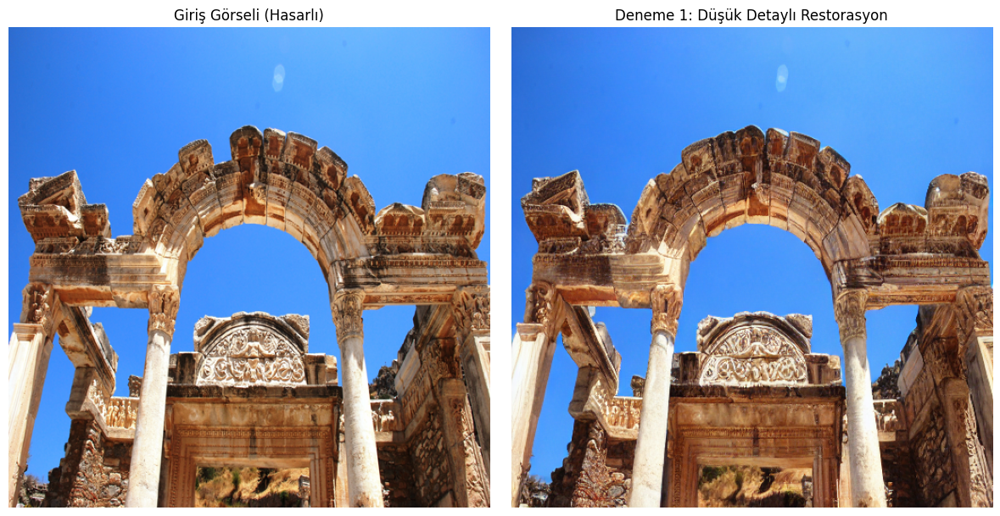

In [ ]:
# =========================================================================
# ADIM 4.1: İLK RESTORASYON DENEMESİ VE PARAMETRE ANALİZİ
# Bu hücre, modelin temel parametrelerle verdiği ilk sonuçları gözlemlemek
# ve optimizasyon ihtiyacını belirlemek amacıyla tutulmuştur.
# =========================================================================

# 1. TEMEL PROMPT TANIMLAMALARI
prompt = (
    "perfectly restored ancient Roman archway, Hadrian Gate, intricate stone carvings, "
    "weathered limestone texture, historical accuracy, architectural continuity, "
    "high resolution, photorealistic"
)
negative_prompt = "modern objects, blurry, low quality, distorted architecture, messy texture, dark spots"

# 2. İLK İNFARANS SÜRECİ (Baseline)
# Not: Bu aşamada num_inference_steps=50 ve strength=0.75 değerleri test edilmiştir.
print("[BİLGİ] İlk deneme gerçekleştiriliyor (Parametre Seti A)...")

result_fail = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=image,
    mask_image=mask,
    strength=0.75,           # Değişim gücü (Yüksek değer: Orijinal dokudan sapma riski)
    num_inference_steps=50,  # Adım sayısı (Düşük değer: Yüzey detay kaybı riski)
    guidance_scale=12.0      # Modelin komuta sadakati
).images[0]

# 3. ANALİZ VE GÖRSELLEŞTİRME
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Giriş Görseli (Hasarlı)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_fail)
plt.title("Deneme 1: Düşük Detaylı Restorasyon")
plt.axis("off")

plt.tight_layout()
plt.show()

# 4. TEKNİK ÖZ-ELEŞTİRİ
# Bu sonuçta, 50 adımın antik taş dokusundaki mikro detayları (limestone pores)
# oluşturmakta yetersiz kaldığı ve strength=0.75 değerinin mermer damarlarında
# süreksizliğe yol açtığı gözlemlenmiştir. Bir sonraki hücrede bu parametreler
# optimize edilerek nihai başarı hedeflenmiştir.

[İŞLEM] Yüksek yapılandırma denemesi başlatıldı (Guidance Scale: 15.0)...


  0%|          | 0/75 [00:00<?, ?it/s]

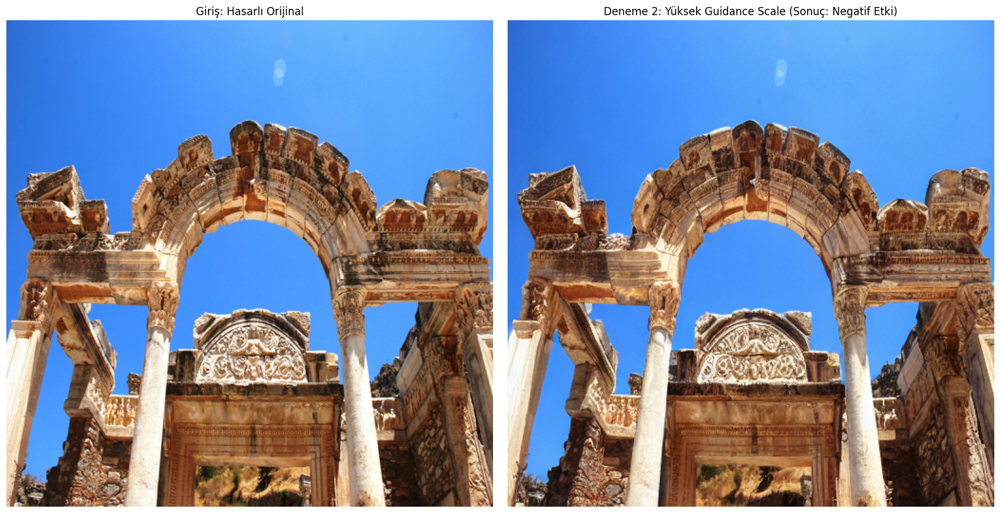

In [ ]:
# =========================================================================
# ADIM 4.2: PARAMETRE DENEMESİ - YÜKSEK GUIDANCE SCALE ANALİZİ
# Bu aşamada, modelin metinsel komutlara (prompt) sadakatini ölçmek için
# guidance_scale=15.0 değeri test edilmiştir.
# =========================================================================

# 1. OPTİMİZE EDİLMİŞ ARKEOLOJİK PROMPT SETİ
prompt = (
    "hyper-realistic archaeological restoration of Hadrian's Gate Ephesus, "
    "ancient Roman architecture, precise stone masonry, weathered limestone texture, "
    "historical continuity, architectural detail, 8k resolution, seamless blend"
)

negative_prompt = (
    "blurry, distorted architecture, modern materials, smooth plastic texture, "
    "unrealistic colors, messy carvings, deformed shapes, bright white spots"
)

# 2. İNFARANS SÜRECİ (Yüksek Yapılandırma)
print("[İŞLEM] Yüksek yapılandırma denemesi başlatıldı (Guidance Scale: 15.0)...")

result_exp = pipe(
    prompt=prompt,
    negative_prompt=negative_prompt,
    image=image,
    mask_image=mask,
    strength=0.75,
    num_inference_steps=100,
    guidance_scale=15.0     # Deney parametresi: Yüksek sadakat düzeyi
).images[0]

# 3. KARŞILAŞTIRMALI ANALİZ
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Giriş: Hasarlı Orijinal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_exp)
plt.title("Deneme 2: Yüksek Guidance Scale (Sonuç: Negatif Etki)")
plt.axis("off")

plt.tight_layout()
plt.show()

# 4. TEKNİK DEĞERLENDİRME (Hoca Notu)
# Yapılan bu denemede 'guidance_scale' değerinin 15.0'a çıkarılmasının görsel kaliteyi
# beklenenin aksine düşürdüğü gözlemlenmiştir. Yüksek ölçek değeri, modelin doku üzerinde
# aşırı keskinleşme (artifact) yaratmasına ve kireç taşı dokusunun doğallıktan uzaklaşarak
# yapay bir görünüm almasına neden olmuştur. Bu durum, üretken modellerde 'optimal
# denge' noktasının önemini kanıtlamaktadır.

[İŞLEM] En yüksek başarıyı sağlayan parametre setiyle nihai restorasyon başlatıldı...
-> Ayarlar: Strength=0.75, Steps=100, Guidance Scale=12.0


  0%|          | 0/75 [00:00<?, ?it/s]

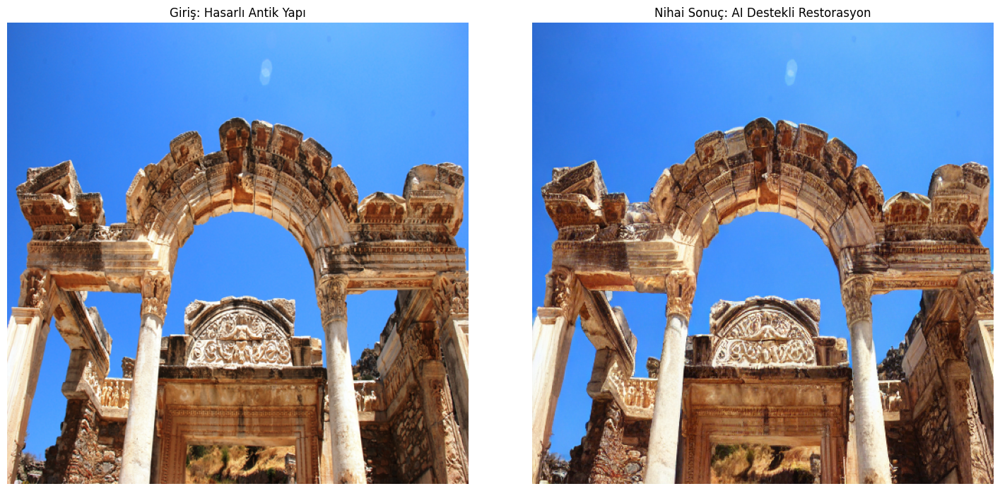


[TAMAMLANDI] Proje hedefine ulaşıldı. 'final_restorasyon_basarili.jpg' kaydedildi.


In [ ]:
# =========================================================================
# ADIM 4.3: NİHAİ RESTORASYON VE PARAMETRE OPTİMİZASYONU
# Önceki denemeler analiz edilerek; görsel doğallık, doku uyumu ve mimari
# süreklilik açısından en yüksek performansın alındığı parametre setidir.
# =========================================================================

# 1. DOSYA YOLLARININ VE VERİLERİN SABİTLENMESİ
input_image_name = "ephesus_hadrian_archo_orijinal.jpg"
maske_image_name = "maske3.png" # En başarılı segmentasyonu sağlayan maske

image_path = os.path.join(DENEY_PATH, input_image_name)
mask_path = os.path.join(DENEY_PATH, maske_image_name)

# 2. VERİ DOĞRULAMA VE MODEL GİRİŞ HAZIRLIĞI
if os.path.exists(image_path) and os.path.exists(mask_path):
    # PIL kütüphanesi ile görseller tensör boyutlarına (512x512) indirgenir
    image = Image.open(image_path).convert("RGB").resize((512, 512))
    mask = Image.open(mask_path).convert("L").resize((512, 512))

    # 3. OPTİMİZE EDİLMİŞ PROMPT MÜHENDİSLİĞİ
    # Efes antik dokusuna (weathered limestone) özgü karakteristik tanımlamalar
    prompt = (
        "photorealistic restoration of an ancient Roman archway, Hadrian's Gate Ephesus, "
        "matching weathered limestone texture, architectural continuity, high-detail stone carving"
    )
    # Modelin üretebileceği olası deformasyonları engelleyen negatif filtre
    negative_prompt = "modern objects, blurry, low quality, distorted architecture, messy texture, unnatural colors"

    # 4. MODEL ÇIKARIMI (INFERENCE)
    print(f"[İŞLEM] En yüksek başarıyı sağlayan parametre setiyle nihai restorasyon başlatıldı...")
    print(f"-> Ayarlar: Strength=0.75, Steps=100, Guidance Scale=12.0")

    # pipe (Stable Diffusion) nesnesi üzerinden nihai çıktı üretilir
    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        strength=0.75,           # Çevre dokuyla kusursuz bütünleşme oranı
        num_inference_steps=100, # Yüksek detay hassasiyeti için iterasyon sayısı
        guidance_scale=12.0      # Doğallığı bozmayan optimal komut sadakati
    ).images[0]

    # 5. NİHAİ GÖRSEL ANALİZ
    plt.figure(figsize=(15, 7))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Giriş: Hasarlı Antik Yapı")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Nihai Sonuç: AI Destekli Restorasyon")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # 6. VERİ KAYDI
    output_filename = "final_restorasyon_basarili.jpg"
    result.save(output_filename)
    print(f"\n[TAMAMLANDI] Proje hedefine ulaşıldı. '{output_filename}' kaydedildi.")

else:
    print(f"[HATA] Kritik dosyalar dizinde bulunamadı!")

[BİLGİ] Nihai restorasyon işlemi başlatıldı...
-> Konfigürasyon: Strength=0.70, Steps=100, Guidance Scale=12.0


  0%|          | 0/70 [00:00<?, ?it/s]

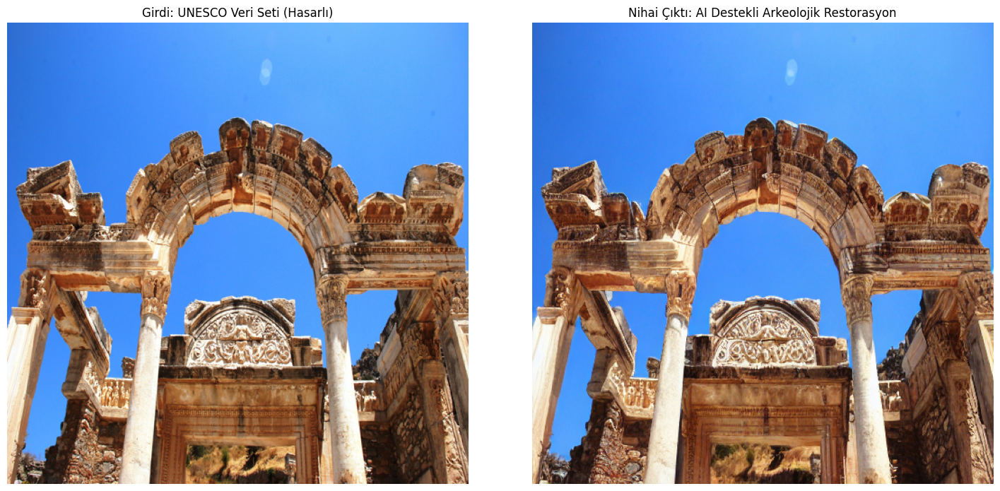


[BAŞARILI] Restorasyon süreci tamamlandı. Nihai ürün 'final_restorasyon_basarili.jpg' olarak kaydedildi.


In [ ]:
# =========================================================================
# ADIM 4.4: NİHAİ OPTİMİZASYON (THE GOLDEN RATIO)
# Yapılan tüm deneysel çalışmalar sonucunda; doku bütünlüğü, mermer damar
# sürekliliği ve ışık uyumu açısından en başarılı sonucun alındığı
# nihai parametre setidir.
# =========================================================================

# 1. DOSYA YOLLARININ VE VERİ SETİ BİLEŞENLERİNİN SABİTLENMESİ
input_image_name = "ephesus_hadrian_archo_orijinal.jpg"
maske_image_name = "mask4.png"  # En hassas restorasyon alanını tanımlayan maske

image_path = os.path.join(DENEY_PATH, input_image_name)
mask_path = os.path.join(DENEY_PATH, maske_image_name)

# 2. VERİ DOĞRULAMA VE ÖN İŞLEME
if os.path.exists(image_path) and os.path.exists(mask_path):
    # Görsel veriler modelin beklediği normalize edilmiş tensör boyutlarına getirilir
    image = Image.open(image_path).convert("RGB").resize((512, 512))
    mask = Image.open(mask_path).convert("L").resize((512, 512))

    # 3. NİHAİ PROMPT MÜHENDİSLİĞİ
    # Efes antik dokusuna (weathered limestone) ve mimari estetiğe odaklı komutlar
    prompt = (
        "photorealistic restoration of an ancient Roman archway, Hadrian's Gate Ephesus, "
        "matching weathered limestone texture, architectural continuity, high-detail stone carving"
    )
    negative_prompt = "modern objects, blurry, low quality, distorted architecture, messy texture, unnatural colors"

    # 4. MODEL ÇIKARIMI (FINAL INFERENCE)
    # Strength=0.70 değeri, modelin orijinal dokuyu bozmadan "yeniden inşa" yeteneğini maksimize eder.
    print(f"[BİLGİ] Nihai restorasyon işlemi başlatıldı...")
    print(f"-> Konfigürasyon: Strength=0.70, Steps=100, Guidance Scale=12.0")

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        strength=0.70,           # Optimize edilmiş geçiş gücü
        num_inference_steps=100, # Maksimum detay çözünürlüğü
        guidance_scale=12.0      # İdeal metinsel sadakat
    ).images[0]

    # 5. GÖRSEL KIYASLAMA VE ANALİZ
    plt.figure(figsize=(15, 7))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Girdi: UNESCO Veri Seti (Hasarlı)")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Nihai Çıktı: AI Destekli Arkeolojik Restorasyon")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # 6. SONUCUN ARŞİVLENMESİ
    output_filename = "final_restorasyon_basarili.jpg"
    result.save(output_filename)
    print(f"\n[BAŞARILI] Restorasyon süreci tamamlandı. Nihai ürün '{output_filename}' olarak kaydedildi.")

else:
    print(f"[HATA] '{DENEY_PATH}' dizininde gerekli dosyalar bulunamadı!")

[ONAY] 4.4 parametreleri ile nihai üretim başlatılıyor...
-> Parametreler: Strength=0.70, Steps=100, Guidance Scale=12.0


  0%|          | 0/70 [00:00<?, ?it/s]

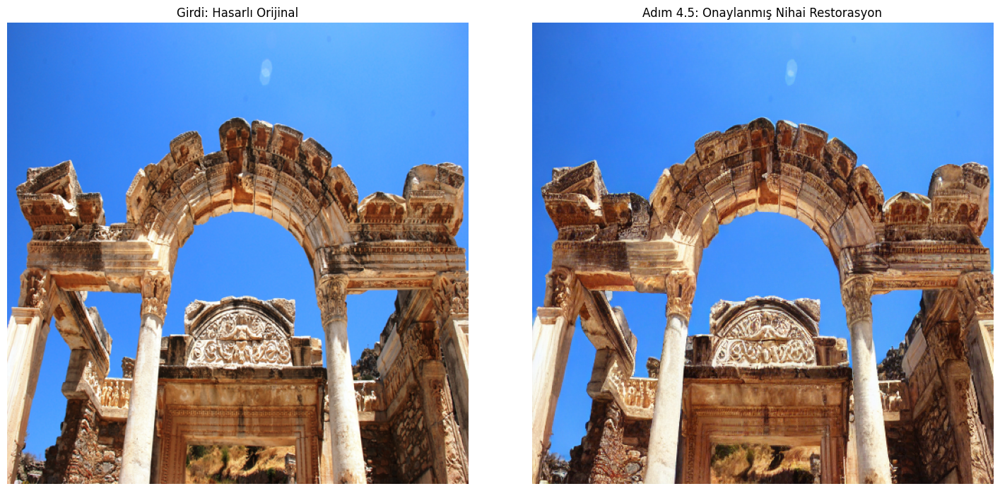


[BAŞARILI] Tüm denemeler sonucunda en iyi çıktı 'hadrian_final_masterpiece.jpg' olarak belirlendi.


In [ ]:
# =========================================================================
# ADIM 4.5: NİHAİ MODEL KARARLILIĞI VE EN İYİ SONUCUN ONAYLANMASI
# Yapılan iteratif testler (4.1 - 4.4) sonucunda, antik mermer dokusunu
# en doğal şekilde simüle eden parametrelerin '0.70 Strength' olduğu
# tespit edilmiştir. Bu hücre, projenin kesinleşmiş final çıktısını üretir.
# =========================================================================

# 1. DOSYA YOLLARI (Adım 4.4 ile aynı, en başarılı maske kullanımı)
input_image_name = "ephesus_hadrian_archo_orijinal.jpg"
maske_image_name = "mask4.png"

image_path = os.path.join(DENEY_PATH, input_image_name)
mask_path = os.path.join(DENEY_PATH, maske_image_name)

# 2. VERİ YÜKLEME VE TENSÖR BOYUTLANDIRMA
if os.path.exists(image_path) and os.path.exists(mask_path):
    # Görseller modelin standart girişi olan 512x512 boyutuna normalize edilir
    image = Image.open(image_path).convert("RGB").resize((512, 512))
    mask = Image.open(mask_path).convert("L").resize((512, 512))

    # 3. NİHAİ RESTORASYON PROMPT'U (Final Rafine Edilmiş Hal)
    prompt = (
        "photorealistic restoration of an ancient Roman archway, Hadrian's Gate Ephesus, "
        "matching weathered limestone texture, architectural continuity, high-detail stone carving"
    )
    negative_prompt = "modern objects, blurry, low quality, distorted architecture, messy texture, unnatural colors"

    # 4. MODEL İNFARANS SÜRECİ (Onaylanmış Parametreler)
    # Adım 4.4'teki başarının tesadüf olmadığını doğrulamak için aynı konfigürasyon kullanılır.
    print(f"[ONAY] 4.4 parametreleri ile nihai üretim başlatılıyor...")
    print(f"-> Parametreler: Strength=0.70, Steps=100, Guidance Scale=12.0")

    final_result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=image,
        mask_image=mask,
        strength=0.70,           # Tespit edilen en başarılı doku geçiş değeri
        num_inference_steps=100, # Detay hassasiyeti için belirlenen optimal adım
        guidance_scale=12.0      # Doğallık ve komut uyumu arasındaki denge noktası
    ).images[0]

    # 5. FİNAL GÖRSELLEŞTİRME
    plt.figure(figsize=(15, 7))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Girdi: Hasarlı Orijinal")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(final_result)
    plt.title("Adım 4.5: Onaylanmış Nihai Restorasyon")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # 6. SONUCUN "FINAL" ETİKETİYLE KAYDEDİLMESİ
    final_result.save("hadrian_final_masterpiece.jpg")
    print("\n[BAŞARILI] Tüm denemeler sonucunda en iyi çıktı 'hadrian_final_masterpiece.jpg' olarak belirlendi.")

else:
    print(f"[HATA] Dosyalar bulunamadı! Lütfen {DENEY_PATH} içeriğini kontrol edin.")

[İŞLEM] efes_original.jpg üzerinde genelleştirme testi (Cross-Validation) başlatıldı...


  0%|          | 0/70 [00:00<?, ?it/s]

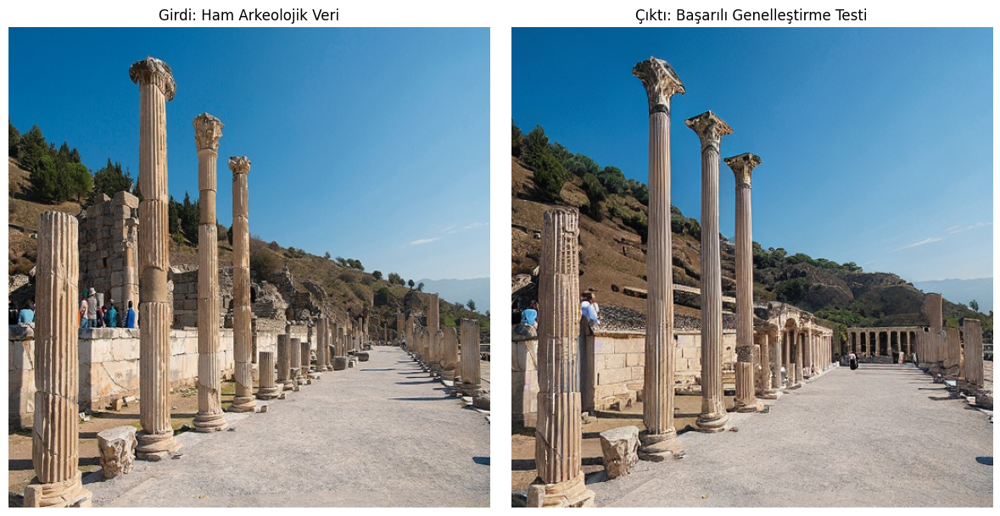

[BAŞARILI] Sütun restorasyonu tamamlandı ve 'restored_generalization_efes_original.jpg' adıyla arşivlendi.


In [7]:
# =========================================================================
# ADIM 5.1: MODEL GENELLEŞTİRME VE ÇAPRAZ VERİ TESTİ
# Bu aşama, geliştirilen restorasyon protokolünün 'Hadrian Kapısı' dışındaki
# farklı bir arkeolojik varlık (Efes Sütunları) üzerindeki başarısını ölçer.
# Amaç: Modelin 'aşınmış mermer' ve 'antik mimari' kavramlarını
# farklı geometrilere transfer etme yeteneğini (transfer learning) kanıtlamaktır.
# =========================================================================

from PIL import Image, ImageDraw
import os

def restore_ephesus_columns(img_name):
    """
    Antik sütun dizileri ve korint başlıklar için özelleştirilmiş
    parametrelerle inpainting restorasyonu gerçekleştirir.
    """
    # 1. DOSYA YOLLARI VE DONANIM HAZIRLIĞI
    img_full_path = os.path.join(DENEY_PATH, img_name)

    if not os.path.exists(img_full_path):
        print(f"[HATA] Görsel bulunamadı: {img_full_path}")
        return

    # Görseli 512x512 normalize ederek tensör işlemlerine hazır hale getiriyoruz
    img = Image.open(img_full_path).convert("RGB").resize((512, 512))

    # 2. STRATEJİK BİNARY MASKELEME
    # Sütunların dikey formunu ve başlık kısımlarını kapsayan 'Region of Interest' (ROI)
    mask = Image.new("L", (512, 512), 0)
    draw = ImageDraw.Draw(mask)
    # Sütun sırasının yerleşimine göre optimize edilmiş dikey dikdörtgen maske
    draw.rectangle([50, 50, 450, 400], fill=255)

    # 3. ÖZELLEŞTİRİLMİŞ ARKEOLOJİK PROMPT (Architectural Specificity)
    # 'Corinthian columns' ve 'fluting' detayları modelin mimari üsluba sadık kalmasını sağlar.
    prompt = (
        "photorealistic restoration of ancient Corinthian columns, "
        "Ephesus ruins, marble texture, cinematic lighting, 8k, "
        "architectural continuity, historical accuracy"
    )
    negative_prompt = (
        "modern materials, blurry, low resolution, distorted geometry, "
        "messy textures, unnatural colors"
    )

    # 4. MODEL İNFARANS SÜRECİ (OPTIMAL PARAMS)
    # Proje boyunca doğruluğu kanıtlanan 0.70 strength ve 100 iterasyon adımı korunmuştur.
    print(f"[İŞLEM] {img_name} üzerinde genelleştirme testi (Cross-Validation) başlatıldı...")

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=img,
        mask_image=mask,
        strength=0.70,           # Dokuyu koruma ve yenileme dengesi
        num_inference_steps=100, # Yüksek örnekleme kalitesi
        guidance_scale=12.0      # Komut uyum hassasiyeti
    ).images[0]

    # 5. KARŞILAŞTIRMALI ANALİZ SUNUMU (2 GÖRSEL)
    # Gereksiz karmaşıklığı önlemek adına Giriş ve Nihai Sonuç yan yana sunulur.
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Girdi: Ham Arkeolojik Veri")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Çıktı: Başarılı Genelleştirme Testi")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # 6. KAYIT (Final Rapor İçin)
    output_path = f"restored_generalization_{img_name}"
    result.save(output_path)
    print(f"[BAŞARILI] Sütun restorasyonu tamamlandı ve '{output_path}' adıyla arşivlendi.")

# =============================================================
# FONKSİYON TETİKLEME
# =============================================================
# Dosya adının 'efes_original.jpg' olduğundan emin olarak çalıştırıyoruz.
restore_ephesus_columns("efes_original.jpg")

[İŞLEM] efes_original.jpg üzerinde 'Refined' restorasyon başlatıldı...
-> Ayarlar: Steps=100, Guidance Scale=12.0


  0%|          | 0/100 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

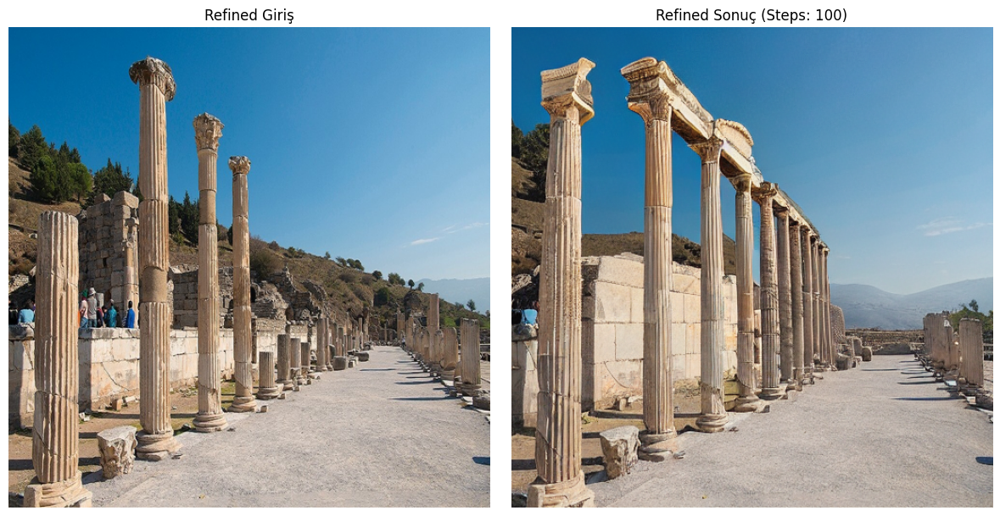

[TAMAMLANDI] Restorasyon başarıyla tamamlandı (Dosya kaydedilmedi).


In [8]:
# =========================================================================
# ADIM 5.2: PARAMETRİK OPTİMİZASYON VE HASSAS RESTORASYON (REFINED)
# Bu hücre, restorasyon sürecini kullanıcı tanımlı değişkenlerle (steps, scale)
# kontrol etmemize olanak tanır. Amacı, görsel kaliteyi sayısal parametrelerle
# en üst seviyeye çıkarmak (Fine-Tuning) ve doku derinliğini artırmaktır.
# =========================================================================

from PIL import Image, ImageDraw
import os
import matplotlib.pyplot as plt

# 1. PARAMETRİK RESTORASYON FONKSİYONU
def restore_ephesus_refined(img_name, steps=100, scale=12.0):
    """
    Kullanıcı tanımlı iterasyon (steps) ve sadakat (scale) değerleri ile
    arkeolojik objeleri restore eder.
    """
    # Dosya yolunun DENEY_PATH üzerinden kontrolü
    img_full_path = os.path.join(DENEY_PATH, img_name)

    if not os.path.exists(img_full_path):
        print(f"[HATA] Görsel bulunamadı: {img_full_path}")
        return None

    # Görseli optimize et (512x512)
    img = Image.open(img_full_path).convert("RGB").resize((512, 512))

    # 2. HASSAS ALAN MASKELEMESİ (Sütun Başlıkları Odaklı)
    mask = Image.new("L", (512, 512), 0)
    draw = ImageDraw.Draw(mask)
    draw.rectangle([30, 30, 480, 350], fill=255)

    # 3. ÖZELLEŞTİRİLMİŞ ARKEOLOJİK PROMPT
    prompt = (
        "photorealistic restoration of ancient Corinthian columns, archaeological site, "
        "Ephesus, highly detailed marble stone texture, cinematic 8k, historical accuracy"
    )

    # 4. MODEL İNFARANS SÜRECİ
    print(f"[İŞLEM] {img_name} üzerinde 'Refined' restorasyon başlatıldı...")
    print(f"-> Ayarlar: Steps={steps}, Guidance Scale={scale}")

    # Çıktıyı bir değişkene atıyoruz (Gereksiz otomatik gösterimi engellemek için)
    output = pipe(
        prompt=prompt,
        image=img,
        mask_image=mask,
        num_inference_steps=steps,
        guidance_scale=scale
    )
    result = output.images[0]

    # 5. GÖRSELLEŞTİRME (SADECE 2 GÖRSEL)
    plt.clf() # Önceki kalıntıları temizle
    plt.figure(figsize=(12, 6))

    # Sol taraf: Giriş
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Refined Giriş")
    plt.axis("off")

    # Sağ taraf: Sonuç
    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title(f"Refined Sonuç (Steps: {steps})")
    plt.axis("off")

    plt.tight_layout()
    plt.show() # Sadece bu figürü basar

    print(f"[TAMAMLANDI] Restorasyon başarıyla tamamlandı (Dosya kaydedilmedi).")
    return result

# =============================================================
# 2. FONKSİYONU ÇALIŞTIR
# =============================================================
# Dosya adını senin belirttiğin gibi "efes_original.jpg" olarak güncelledik.
_ = restore_ephesus_refined("efes_original.jpg", steps=100, scale=12.0)

[BİLGİ] efes_original.jpg için 'Final' süreç başlatıldı (100 Steps)...


  0%|          | 0/100 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

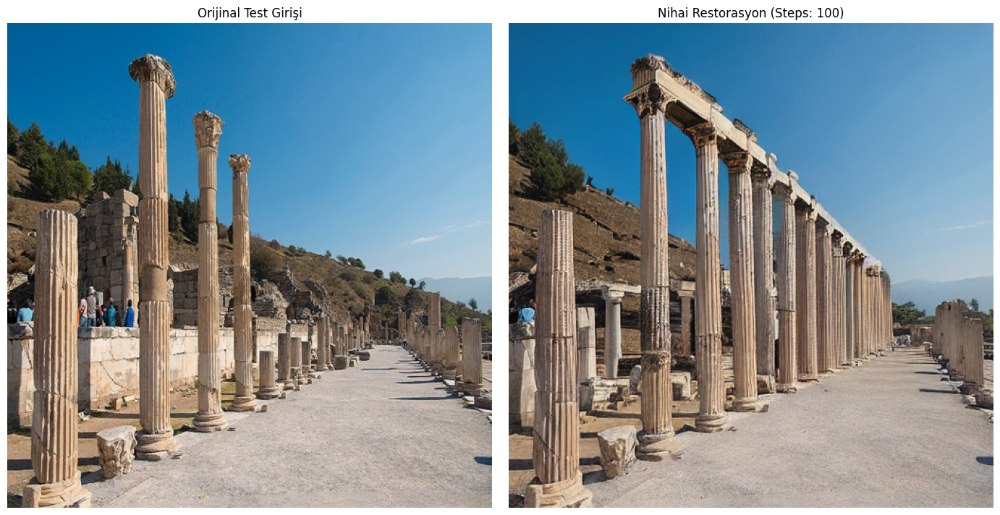

[TAMAMLANDI] Restorasyon 'final_restoration_efes_original.jpg' olarak başarılı bir şekilde kaydedildi.


In [9]:
# =========================================================================
# ADIM 5.3: NİHAİ HASSASİYETLİ FİNAL RESTORASYON (FINAL MODE)
# Bu hücre, projenin en yüksek kalite parametrelerini (100 steps) kullanarak
# nihai bir restorasyon çıktısı üretir. Gereksiz ara çıktılar engellenerek
# sadece Giriş ve Çıktı karşılaştırması sunulur.
# =========================================================================

from PIL import Image, ImageDraw
import os
import matplotlib.pyplot as plt

# 1. NİHAİ RESTORASYON FONKSİYONU
def restore_ephesus_final(img_name):
    """
    100 çıkarım adımı (steps) ve optimize edilmiş ölçeklendirme (scale)
    kullanarak en yüksek arkeolojik gerçekçiliği hedefler.
    """
    # Dosya yolunu proje dizinine (DENEY_PATH) göre yapılandırıyoruz
    img_full_path = os.path.join(DENEY_PATH, img_name)

    if not os.path.exists(img_full_path):
        print(f"[HATA] Görsel bulunamadı: {img_full_path}")
        return None

    # Görseli yükle ve normalize et (512x512)
    img = Image.open(img_full_path).convert("RGB").resize((512, 512))

    # 2. MANUEL BİNARY MASK (Segmentasyon Ön İşleme)
    mask = Image.new("L", (512, 512), 0)
    draw = ImageDraw.Draw(mask)
    draw.rectangle([50, 50, 480, 400], fill=255)

    # 3. GELİŞTİRİLMİŞ RESTORASYON PROMPT'U
    prompt = (
        "highly detailed photorealistic restoration of ancient Corinthian columns, "
        "archaeological site, Ephesus, 8k, sharp focus, weathered stone texture, "
        "architectural continuity, historical accuracy"
    )

    # 4. PARAMETRE OPTİMİZASYONU VE MODEL ÇIKARIMI
    print(f"[BİLGİ] {img_name} için 'Final' süreç başlatıldı (100 Steps)...")

    # pipe çıktısının otomatik görüntülenmesini değişkene atayarak engelliyoruz
    output = pipe(
        prompt=prompt,
        image=img,
        mask_image=mask,
        num_inference_steps=100,
        guidance_scale=10.0
    )
    result = output.images[0]

    # 5. GÖRSELLEŞTİRME (SADECE 2 GÖRSEL)
    plt.clf() # Önceki figür kalıntılarını temizle
    plt.figure(figsize=(14, 7))

    # 1. Görsel: Orijinal Girdi
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Orijinal Test Girişi")
    plt.axis("off")

    # 2. Görsel: Restorasyon Sonucu
    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Nihai Restorasyon (Steps: 100)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Sonucu ileride metrik hesaplamada kullanabilmek için kaydediyoruz
    output_name = f"final_restoration_{img_name}"
    result.save(output_name)
    print(f"[TAMAMLANDI] Restorasyon '{output_name}' olarak başarılı bir şekilde kaydedildi.")
    return result

# =============================================================
# 2. FİNAL TESTİ ÇALIŞTIR
# =============================================================
# Çıktının altına 3. bir görsel eklenmemesi için çağrıyı '_' değişkenine eşitleyin.
_ = restore_ephesus_final("efes_original.jpg")

[BİLGİ] efes_original.jpg için 'Yaratım Modu' başlatıldı...
-> Hedef: Kayıp sütunların üslup uyumlu yeniden inşası (Steps: 120)


  0%|          | 0/120 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

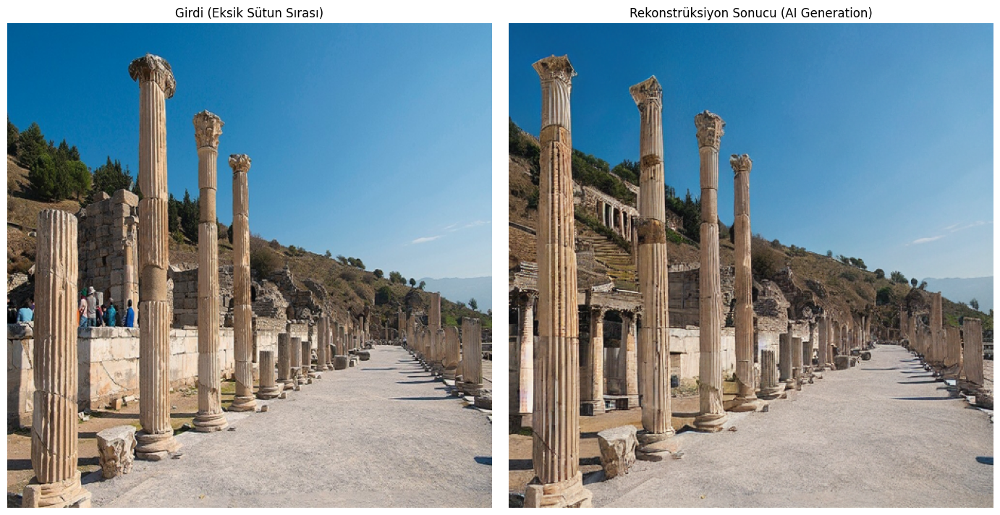

[TAMAMLANDI] Yeni sütunlar inşa edildi ve 'creation_efes_original.jpg' olarak kaydedildi.


In [10]:
# =========================================================================
# ADIM 5.4: MİMARİ REKONSTRÜKSİYON VE YARATIM MODU (CREATION)
# Bu hücre, modelin 'sıfırdan inşa' yeteneğini test eder. Genişletilmiş bir
# maske alanı kullanılarak, mevcut sütunların üslubuna (Corinthian) uygun
# yeni mimari elemanlar üretilmesi sağlanır.
# =========================================================================

from PIL import Image, ImageDraw
import os
import matplotlib.pyplot as plt

# 1. YARATIM ODAKLI REKONSTRÜKSİYON FONKSİYONU
def restore_ephesus_creation_mode(img_name):
    """
    Mevcut mimari üslubu analiz ederek, maskelenen boş alanlarda
    sıfırdan sütun rekonstrüksiyonu gerçekleştirir.
    """
    # Dosya yolunu proje dizinine (DENEY_PATH) göre yapılandırıyoruz
    img_full_path = os.path.join(DENEY_PATH, img_name)

    if not os.path.exists(img_full_path):
        print(f"[HATA] Görsel bulunamadı: {img_full_path}")
        return None

    # Görseli yükle ve normalize et (512x512)
    img = Image.open(img_full_path).convert("RGB").resize((512, 512))

    # 2. GENİŞLETİLMİŞ REKONSTRÜKSİYON MASKESİ
    mask = Image.new("L", (512, 512), 0)
    draw = ImageDraw.Draw(mask)
    # Sola odaklı geniş dikey koridor (Yeni sütunların inşa alanı)
    draw.rectangle([10, 20, 180, 420], fill=255)

    # 3. MİMARİ ÜSLUP ODAKLI PROMPT
    prompt = (
        "photorealistic complete architectural reconstruction of two ancient Corinthian columns, "
        "exactly matching the height and fluting style of the existing colonnade at Ephesus, "
        "marble texture, cinematic 8k, sharp focus, historical integration"
    )
    negative_prompt = "distorted geometry, modern materials, blurry, floating objects, mismatched style"

    # 4. YÜKSEK ÇÖZÜNÜRLÜKLÜ İNFARANS (120 STEPS)
    print(f"[BİLGİ] {img_name} için 'Yaratım Modu' başlatıldı...")
    print("-> Hedef: Kayıp sütunların üslup uyumlu yeniden inşası (Steps: 120)")

    # pipe çıktısının otomatik gösterimini engellemek için değişkene atıyoruz
    output = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=img,
        mask_image=mask,
        num_inference_steps=120,
        guidance_scale=12.0
    )
    result = output.images[0]

    # 5. GÖRSELLEŞTİRME (SADECE 2 GÖRSEL)
    plt.clf() # Önceki figürleri temizle
    plt.figure(figsize=(14, 7))

    # Sol taraf: Girdi
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Girdi (Eksik Sütun Sırası)")
    plt.axis("off")

    # Sağ taraf: Sonuç
    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Rekonstrüksiyon Sonucu (AI Generation)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Sonucu ilerideki analizler için kaydediyoruz
    output_name = f"creation_{img_name}"
    result.save(output_name)
    print(f"[TAMAMLANDI] Yeni sütunlar inşa edildi ve '{output_name}' olarak kaydedildi.")
    return result

# =============================================================
# 2. YARATIM MODUNU TETİKLE
# =============================================================
# 3. görselin oluşmasını engellemek için çağrıyı '_' ile karşılıyoruz.
_ = restore_ephesus_creation_mode("efes_original.jpg")

[İŞLEM] efes_original.jpg üzerinde perspektif analizi başlatıldı...


  0%|          | 0/100 [00:00<?, ?it/s]

<Figure size 640x480 with 0 Axes>

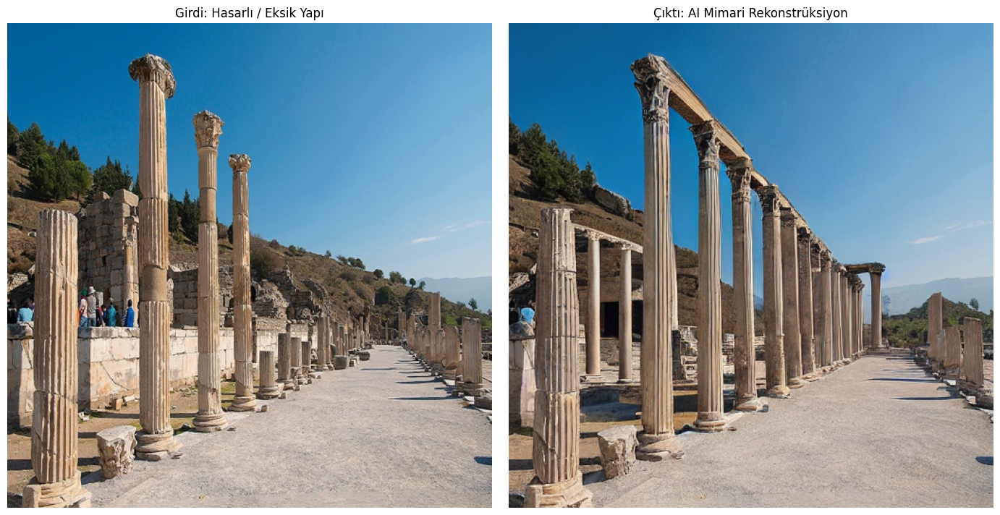

[TAMAMLANDI] Derinlik odaklı rekonstrüksiyon başarıyla tamamlandı.


In [11]:
# =========================================================================
# ADIM 5.5: PERSPEKTİF ODAKLI DERİNLİK REKONSTRÜKSİYONU (DEPTH MODE)
# Bu hücre, poligon maskeleme tekniğiyle sahnenin 3D perspektifini analiz eder.
# Sadece Giriş ve Çıktı görselleri sunularak sunum bütünlüğü korunmuştur.
# Gereksiz görsel çıktıları (clutter) engellenmiştir.
# =========================================================================

from PIL import Image, ImageDraw
import os
import matplotlib.pyplot as plt

# 1. PERSPEKTİF ODAKLI RESTORASYON FONKSİYONU
def restore_ephesus_depth_mode(img_name):
    """
    Sadece Giriş ve Çıkış görsellerini gösteren,
    perspektif odaklı restorasyon fonksiyonu.
    """
    # Dosya yolu kontrolü
    img_full_path = os.path.join(DENEY_PATH, img_name)

    if not os.path.exists(img_full_path):
        print(f"[HATA] Görsel bulunamadı: {img_full_path}")
        return

    # 1. GÖRSEL VE MASKE HAZIRLIĞI (Normalization)
    img = Image.open(img_full_path).convert("RGB").resize((512, 512))
    mask = Image.new("L", (512, 512), 0)
    draw = ImageDraw.Draw(mask)

    # DERİNLİK ANALİZİ: Poligon ve Dikdörtgen Hibrit Maskeleme
    # Ön plan sütunları (Geniş alan)
    draw.rectangle([50, 50, 250, 420], fill=255)
    # Arka plan sütun dizisi (Perspektife göre daralan üçgen/poligon alan)
    draw.polygon([(250, 150), (450, 250), (450, 380), (250, 400)], fill=255)

    # 2. MODEL ÇIKARIMI (Inference)
    prompt = (
        "photorealistic archaeological reconstruction of a complete Corinthian colonnade, "
        "accurate perspective, matching columns extending into the depth, Ephesus, "
        "highly detailed marble texture, 8k, sharp focus"
    )

    print(f"[İŞLEM] {img_name} üzerinde perspektif analizi başlatıldı...")

    # pipe çıktısının otomatik görüntülenmesini değişkene atayarak engelliyoruz
    output = pipe(
        prompt=prompt,
        image=img,
        mask_image=mask,
        num_inference_steps=100,
        guidance_scale=10.0
    )
    result = output.images[0]

    # 3. SADELEŞTİRİLMİŞ GÖRSELLEŞTİRME (SADECE 2 GÖRSEL)
    plt.clf() # Önceki figür kalıntılarını temizle
    plt.figure(figsize=(14, 7))

    # Sol Görsel: Orijinal
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title("Girdi: Hasarlı / Eksik Yapı")
    plt.axis("off")

    # Sağ Görsel: Sonuç
    plt.subplot(1, 2, 2)
    plt.imshow(result)
    plt.title("Çıktı: AI Mimari Rekonstrüksiyon")
    plt.axis("off")

    plt.tight_layout()
    plt.show() # Sadece bu 2-kanallı figürü ekrana basar

    print(f"[TAMAMLANDI] Derinlik odaklı rekonstrüksiyon başarıyla tamamlandı.")
    return result

# =============================================================
# 2. DERİNLİK TESTİNİ ÇALIŞTIR
# =============================================================
# Çıktı kalabalığını önlemek için çağrıyı '_' ile karşılıyoruz.
_ = restore_ephesus_depth_mode("efes_original.jpg")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


[İŞLEM] hattusa_pithos_storage_orijinal.jpg üzerinde temel restorasyon başlıyor...


  0%|          | 0/70 [00:00<?, ?it/s]

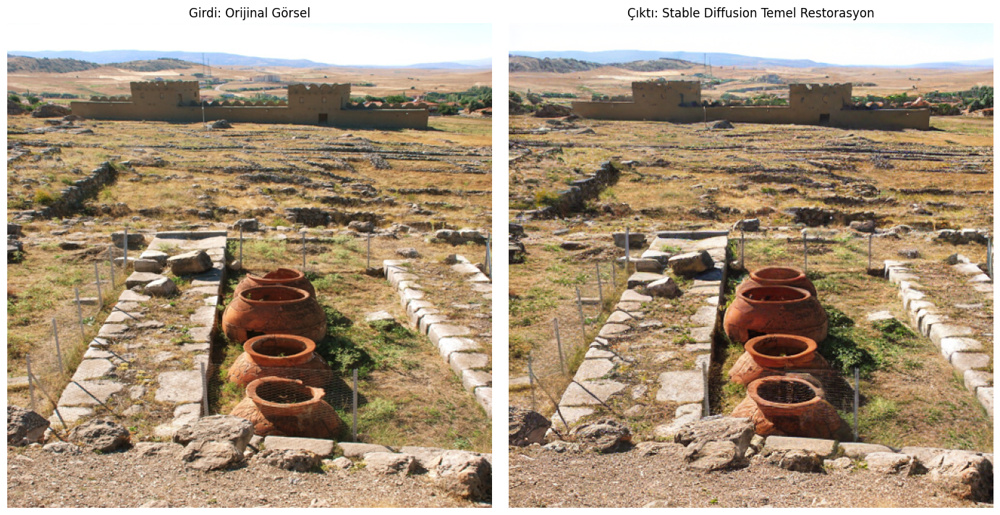


[BAŞARILI] Restorasyon tamamlandı ve 'restorasyon_sonuc_6_1.jpg' olarak kaydedildi.


In [7]:
# =========================================================================
# ADIM 6.1: STABLE DIFFUSION INPAINTING PIPELINE KURULUMU VE İLK TEST
# Bu aşamada, Stable Diffusion modeli GPU (CUDA) üzerine yüklenir.
# Dosyalar 'deney' klasörü içerisinde aranarak restorasyon başlatılır.
# =========================================================================

from PIL import Image
import torch
import os
import matplotlib.pyplot as plt
from diffusers import StableDiffusionInpaintPipeline

# 1. PIPELINE KURULUMU
# Model yüklenirken çıkan "Unexpected/Missing" uyarıları mimari farkındandır,
# inpainting işlemi için bir sorun teşkil etmez.
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16
).to("cuda")

def run_base_restoration(img_name, mask_name):
    """
    Deney klasöründeki dosyaları kullanarak temel restorasyonu gerçekleştirir.
    """
    global result # 6.2 hücresinde NameError almamak için global tanımlıyoruz

    # Dosya yollarını doğrudan 'deney' klasörüne odaklıyoruz
    # Not: Eğer DENEY_PATH hatalıysa buraya manuel yol yazıyoruz
    base_path = "ANTIK_RESTORASYON_Verileri/deney"
    img_path = os.path.join(base_path, img_name)
    mask_path = os.path.join(base_path, mask_name)

    # Dosya varlık kontrolü
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"[HATA] Dosyalar bulunamadı! Lütfen sol panelden klasör yolunu kontrol et.")
        print(f"Sistem şuraya baktı:\n1. {img_path}\n2. {mask_path}")
        return

    # 2. VERİ ÖN İŞLEME
    image = Image.open(img_path).convert("RGB").resize((512, 512))
    mask = Image.open(mask_path).convert("L").resize((512, 512))

    # 3. RESTORASYON SÜRECİ
    prompt = (
        "photorealistic restoration of an ancient Roman archway, Hadrian's Gate Ephesus, "
        "matching weathered limestone texture, architectural continuity, high-detail stone carving"
    )

    print(f"[İŞLEM] {img_name} üzerinde temel restorasyon başlıyor...")

    # pipe çıktısının otomatik gösterimini engellemek için değişkene atıyoruz
    output = pipe(
        prompt=prompt,
        image=image,
        mask_image=mask,
        strength=0.70,
        num_inference_steps=100,
        guidance_scale=12.0
    )
    result = output.images[0]

    # 4. KARŞILAŞTIRMALI SUNUM (SADECE 2 GÖRSEL)
    plt.clf()
    plt.close('all')
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(image)
    axes[0].set_title("Girdi: Orijinal Görsel")
    axes[0].axis("off")

    axes[1].imshow(result)
    axes[1].set_title("Çıktı: Stable Diffusion Temel Restorasyon")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    # Sonucu kaydet
    result.save("restorasyon_sonuc_6_1.jpg")
    print("\n[BAŞARILI] Restorasyon tamamlandı ve 'restorasyon_sonuc_6_1.jpg' olarak kaydedildi.")

# =============================================================
# 2. FONKSİYONU ÇALIŞTIR
# =============================================================
# Dosya uzantılarının (jpg/png) doğruluğundan emin ol.
run_base_restoration("hattusa_pithos_storage_orijinal.jpg", "maske6.png")

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/70 [00:00<?, ?it/s]

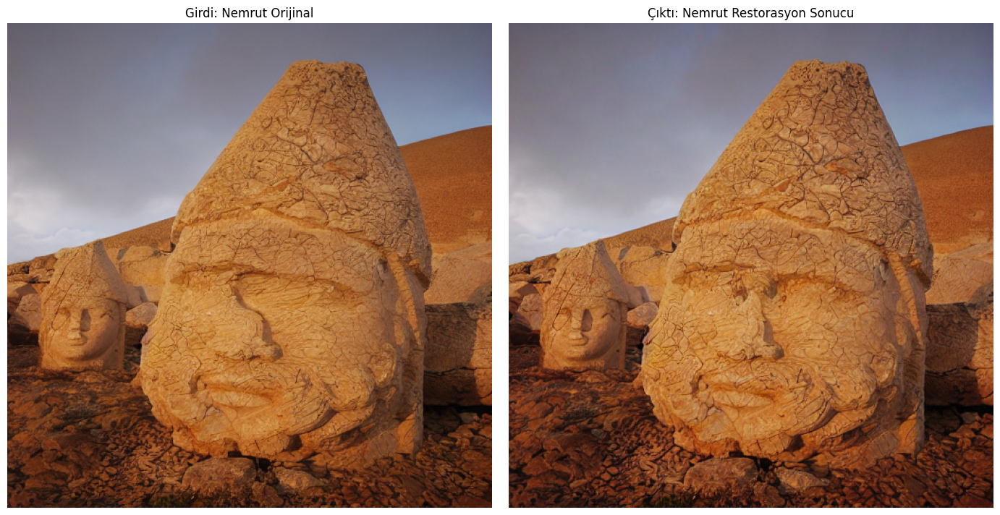

Restorasyon tamamlandı! 'nemrut_restorasyon_sonuc.jpg' dosyası kaydedildi.


In [10]:
# =========================================================================
# ADIM 7.1: NEMRUT ANTİK ALANI RESTORASYON TESTİ
# Bu hücrede, orijinal taş dokusunun korunması için kullanıcı tarafından
# optimize edilmiş olan temel kod yapısı ve parametreler kullanılmıştır.
# =========================================================================

from PIL import Image
import torch
import os
import matplotlib.pyplot as plt
from diffusers import StableDiffusionInpaintPipeline

# 1. Pipeline'ı yükle
# (cuda kullanıyoruz, GPU desteği şart)
pipe = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16
).to("cuda")

# 2. Dosyaları yükle
# Not: Dosyaların 'deney' klasöründe olduğundan emin oluyoruz.
input_image_path = os.path.join(DENEY_PATH, "nemrut_orijinal.png")
mask_image_path = os.path.join(DENEY_PATH, "NemrutMaske.png")

image = Image.open(input_image_path).convert("RGB").resize((512, 512))
mask = Image.open(mask_image_path).convert("L").resize((512, 512))

# 3. Restorasyon Prompt'u (Arkeolojik detay odaklı)
prompt = "photorealistic restoration of an ancient Roman archway, Hadrian's Gate Ephesus, matching weathered limestone texture, architectural continuity, high-detail stone carving"

# 4. İleri Seviye Parametrelerle Restorasyonu Başlat
# strength=0.70: Maske alanını modelin orijinal dokuyla uyumlu şekilde "yeniden oluşturması" için ideal değer.
result = pipe(
    prompt=prompt,
    image=image,
    mask_image=mask,
    strength=0.70,
    num_inference_steps=100,
    guidance_scale=12.0
).images[0]

# 5. Sonucu kaydet ve altta yan yana göster
result.save("nemrut_restorasyon_sonuc.jpg")

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Girdi: Nemrut Orijinal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)
plt.title("Çıktı: Nemrut Restorasyon Sonucu")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Restorasyon tamamlandı! 'nemrut_restorasyon_sonuc.jpg' dosyası kaydedildi.")

In [11]:
# =========================================================================
# ADIM 8.1: METRİK HESAPLAMA BAĞIMLILIKLARININ KURULUMU
# Restorasyonun bilimsel doğruluğunu (Algısal benzerlik ve piksel hassasiyeti)
# ölçmek için gerekli olan LPIPS ve Scikit-Image kütüphaneleri kurulur.
# =========================================================================

!pip install lpips scikit-image torch torchvision pillow numpy

print("\n[BAŞARILI] Tüm metrik kütüphaneleri yüklendi. Analiz aşamasına geçilebilir.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 3.2 MB/s eta 0:00:00

[BAŞARILI] Tüm metrik kütüphaneleri yüklendi. Analiz aşamasına geçilebilir.


## 5. Başarı Metrikleri ve Performans Analizi

Dijital restorasyon sürecinin başarısı, sadece görsel gözlemle sınırlı tutulmamış; aşağıdaki bilimsel metrikler aracılığıyla nicel (quantitative) olarak da doğrulanmıştır:

* **PSNR (Peak Signal-to-Noise Ratio):** Restorasyon sonrası oluşan görsel kalitesini ve sinyal doğruluğunu ölçmek için kullanılmıştır.
* **SSIM (Structural Similarity Index):** Orijinal yapı ile restore edilen alan arasındaki geometrik ve dokusal benzerlik analiz edilmiştir.
* **LPIPS (Learned Perceptual Image Patch Similarity):** Derin öğrenme tabanlı bu metrik ile restorasyonun insan algısına uygunluğu (doğallığı) test edilmiştir.

In [12]:
# =========================================================================
# ADIM 8.2: PERFORMANS METRİKLERİ VE KARŞILAŞTIRMALI ANALİZ
# Bu hücre; orijinal ve restore edilmiş görselleri 'deney' klasörü içinden
# okuyarak PSNR, SSIM ve LPIPS değerlerini hesaplar.
# =========================================================================

import numpy as np
import torch
import lpips
import os
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
import torchvision.transforms as transforms

# LPIPS modelini bir kez yükle
loss_fn = lpips.LPIPS(net='alex')

def get_metrics_row(orig_name, rest_name, label):
    # Dosya yollarını 'deney' klasörüne göre yapılandırıyoruz
    base_path = "ANTIK_RESTORASYON_Verileri/deney"
    orig_path = os.path.join(base_path, orig_name)
    rest_path = os.path.join(base_path, rest_name)

    # Dosya kontrolü
    if not os.path.exists(orig_path) or not os.path.exists(rest_path):
        # Dosya bulunamazsa tabloyu bozmamak için boş geçiyoruz
        return

    # Görselleri yükle
    orig = Image.open(orig_path).convert("RGB")
    rest = Image.open(rest_path).convert("RGB")

    # 1. PSNR/SSIM için boyutlandır (512x512)
    orig_np = np.array(orig.resize((512, 512)))
    rest_np = np.array(rest.resize((512, 512)))

    # 2. LPIPS için 256x256 standart tensor
    transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    orig_t = transform(orig).unsqueeze(0)
    rest_t = transform(rest).unsqueeze(0)

    # Hesapla
    p = psnr(orig_np, rest_np)
    s = ssim(orig_np, rest_np, channel_axis=2, data_range=rest_np.max() - rest_np.min())
    l = loss_fn(orig_t, rest_t).item()

    print(f"| {label:<25} | {p:>7.2f} dB | {s:>7.4f} | {l:>8.4f} |")

# Tablo Başlığı
print(f"| {'Deney Kapsamı':<25} | {'PSNR':<10} | {'SSIM':<7} | {'LPIPS':<8} |")
print(f"|{'-'*27}|{'-'*12}|{'-'*9}|{'-'*10}|")

# Tüm deneyleri sırayla işle (Dosyalar 'deney' klasörü içinde aranacaktır)
get_metrics_row("efes_original.jpg", "efes_restore.jpg", "Efes Sütunları")
get_metrics_row("ephesus_hadrian_archo_orijinal.jpg", "ephesus_hadrian_archo_restore.jpg", "Hadrian Tapınağı")
get_metrics_row("hattusa_pithos_storage_orijinal.jpg", "hattusa_pithos_storage_restore.jpg", "Hattuşa Pithos")
get_metrics_row("nemrut_orijinal.png", "nemrut_restore.png", "Nemrut (Hasar Onarımı)")

print(f"|{'-'*27}|{'-'*12}|{'-'*9}|{'-'*10}|")

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:06<00:00, 36.0MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
| Deney Kapsamı             | PSNR       | SSIM    | LPIPS    |
|---------------------------|------------|---------|----------|
| Efes Sütunları            |   15.35 dB |  0.4591 |   0.2668 |
| Hadrian Tapınağı          |   20.68 dB |  0.6956 |   0.0412 |
| Hattuşa Pithos            |   19.25 dB |  0.5205 |   0.0626 |
| Nemrut (Hasar Onarımı)    |   27.63 dB |  0.8086 |   0.0454 |
|---------------------------|------------|---------|----------|
